# Synaptic Plasticity and Learning Rules
In this notebook, we explore Spike-Timing Dependent Plasticity (STDP) and Hebbian learning.

## 1. Setup and Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 2. Hebbian Learning Concept
Neurons that fire together wire together. We can simulate a simple weight update rule.

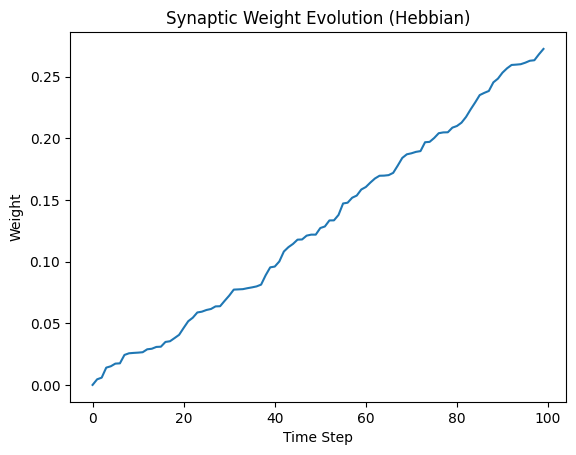

In [2]:
pre_synaptic_activity = np.random.rand(100)
post_synaptic_activity = np.random.rand(100)

learning_rate = 0.01
weights = np.zeros(100)

for i in range(100):
    weights[i] = weights[i-1] + learning_rate * pre_synaptic_activity[i] * post_synaptic_activity[i] if i > 0 else 0

plt.plot(weights)
plt.title('Synaptic Weight Evolution (Hebbian)')
plt.xlabel('Time Step')
plt.ylabel('Weight')
plt.show()

## 3. Spike-Timing Dependent Plasticity (STDP)
STDP changes the synaptic weight based on the relative timing of pre- and post-synaptic spikes.

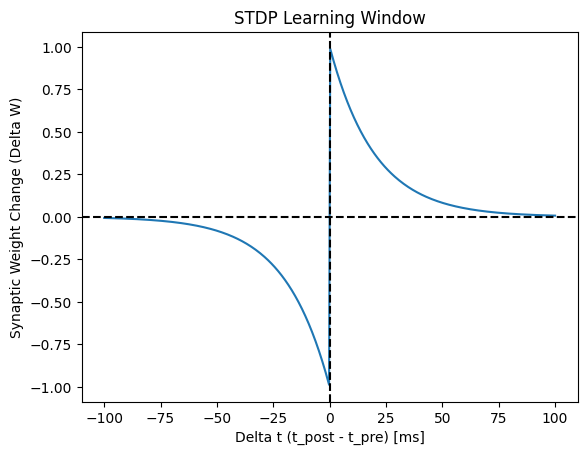

In [3]:
def stdp_weight_change(delta_t, A_plus=1.0, A_minus=-1.0, tau_plus=20.0, tau_minus=20.0):
    if delta_t > 0:
        return A_plus * np.exp(-delta_t / tau_plus)
    else:
        return A_minus * np.exp(delta_t / tau_minus)

delta_ts = np.linspace(-100, 100, 400)
delta_ws = [stdp_weight_change(dt) for dt in delta_ts]

plt.plot(delta_ts, delta_ws)
plt.axhline(0, color='k', linestyle='--')
plt.axvline(0, color='k', linestyle='--')
plt.title('STDP Learning Window')
plt.xlabel('Delta t (t_post - t_pre) [ms]')
plt.ylabel('Synaptic Weight Change (Delta W)')
plt.show()